# Experiment 7: Propagation of a Small Wave on Still Water (Finite-Volume Solution and Parametric Study)
**Aim.** Simulate the splitting and propagation of a small Gaussian disturbance on still water using the linearised shallow-water equations, solved with a cell-centred finite-volume upwind scheme with explicit (forward Euler) and implicit (backward Euler) time stepping. The results are compared with the exact d'Alembert solution, and the effect of the number of cells and of the time step (CFL number) is studied.


## 1. Problem set-up

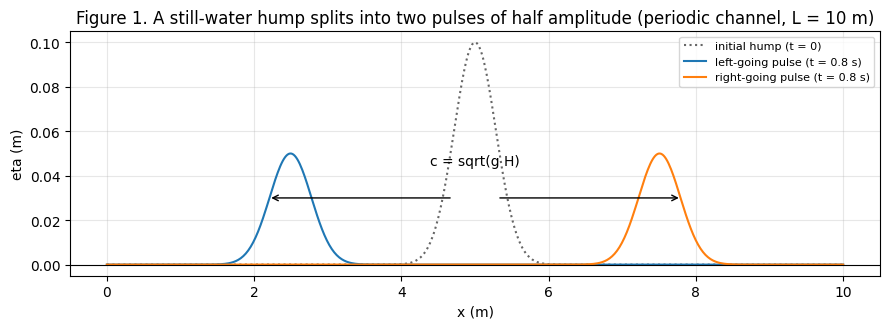

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.sparse import lil_matrix
from scipy.sparse.linalg import factorized

L, H, g = 10.0, 1.0, 9.81            # channel length, depth, gravity
A0, width, t_end = 0.10, 0.40, 0.80  # hump amplitude, width, end time
nx = 200                             # number of cells (baseline)
c = np.sqrt(g * H)                   # wave speed, 3.132 m/s

# Figure 1: schematic
fig, ax = plt.subplots(figsize=(9, 3.4))
xs = np.linspace(0, L, 600)
hump = lambda x0: A0*np.exp(-((xs - x0)/width)**2)
ax.plot(xs, hump(L/2), ':', color='0.4', label='initial hump (t = 0)')
ax.plot(xs, .5*hump(L/2 - c*t_end) , 'C0', label='left-going pulse (t = 0.8 s)')
ax.plot(xs, .5*hump(L/2 + c*t_end), 'C1', label='right-going pulse (t = 0.8 s)')
ax.annotate('', xy=(L/2 - c*t_end - .3, .03), xytext=(L/2 - .3, .03), arrowprops=dict(arrowstyle='->'))
ax.annotate('', xy=(L/2 + c*t_end + .3, .03), xytext=(L/2 + .3, .03), arrowprops=dict(arrowstyle='->'))
ax.text(L/2, .045, 'c = sqrt(g H)', ha='center')
ax.axhline(0, color='k', lw=.8); ax.set(xlabel='x (m)', ylabel='eta (m)', title='Figure 1. A still-water hump splits into two pulses of half amplitude (periodic channel, L = 10 m)')
ax.legend(fontsize=8); ax.grid(alpha=.3); plt.tight_layout(); plt.show()

## 2. Baseline run

Table 1. Baseline output (original script)
N=200; dx=0.05000; dt=0.0126984; CFL=0.795452; wave speed=3.132092
Volume initial  = 0.070898154036
Volume explicit = 0.070898154036; relative error = 0.000e+00
Volume implicit = 0.070898154036; relative error = 6.655e-15
L2 explicit = 0.00581506; L2 implicit = 0.02363066
Peak of the right-going pulse / exact peak: explicit 0.8713, implicit 0.5156


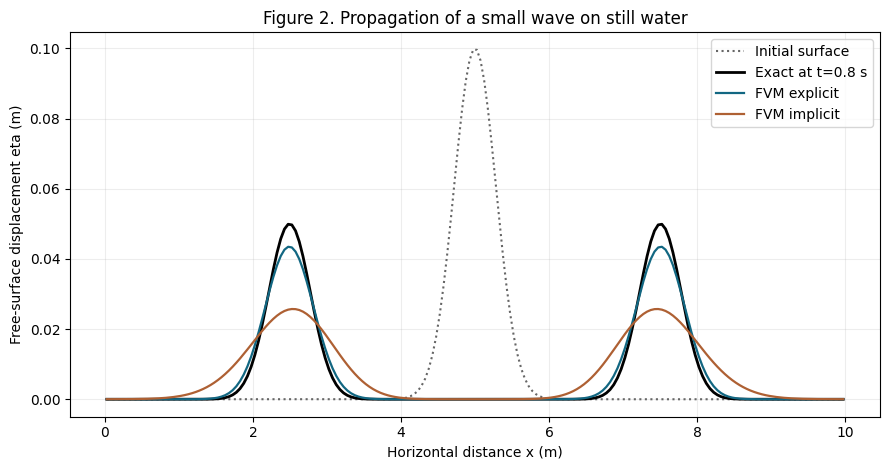

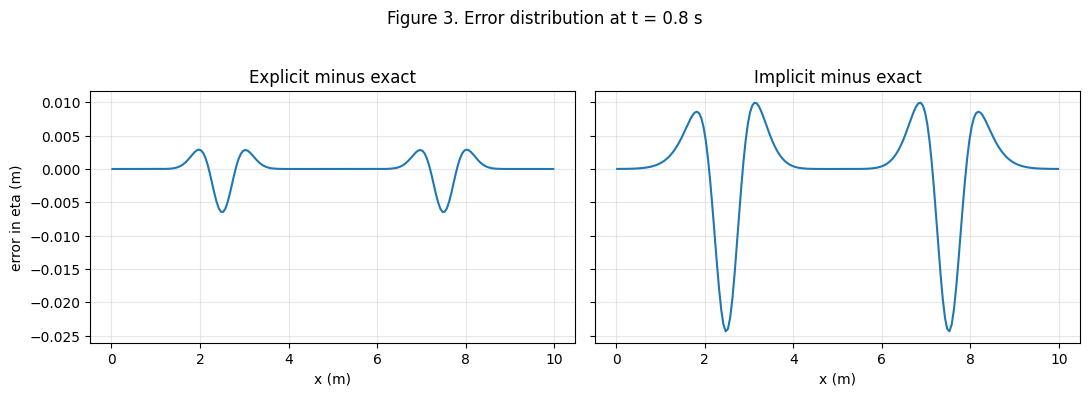

In [2]:
dx = L / nx
dt = t_end / int(np.ceil(t_end * c / (0.8 * dx)))
lam = c * dt / dx
x = (np.arange(nx) + 0.5) * dx
initial = A0 * np.exp(-((x - L/2) / width)**2)

r_exp = initial.copy(); l_exp = initial.copy(); r_imp = initial.copy(); l_imp = initial.copy()
M_r = lil_matrix((nx, nx)); M_l = lil_matrix((nx, nx))
for i in range(nx):
    M_r[i, i] = 1 + lam; M_r[i, (i - 1) % nx] = -lam
    M_l[i, i] = 1 + lam; M_l[i, (i + 1) % nx] = -lam
solve_r = factorized(M_r.tocsc()); solve_l = factorized(M_l.tocsc())

for _ in range(round(t_end / dt)):
    r_exp = r_exp - lam * (r_exp - np.roll(r_exp, 1))
    l_exp = l_exp - lam * (l_exp - np.roll(l_exp, -1))
    r_imp = solve_r(r_imp); l_imp = solve_l(l_imp)

eta_exp = 0.5 * (r_exp + l_exp); eta_imp = 0.5 * (r_imp + l_imp)
eta_exact = 0.5 * A0 * (np.exp(-((x - L/2 - c*t_end)/width)**2) + np.exp(-((x - L/2 + c*t_end)/width)**2))
vol_0, vol_exp, vol_imp = dx*np.sum(initial), dx*np.sum(eta_exp), dx*np.sum(eta_imp)
l2_exp = np.sqrt(dx*np.sum((eta_exp - eta_exact)**2)); l2_imp = np.sqrt(dx*np.sum((eta_imp - eta_exact)**2))

print('Table 1. Baseline output (original script)')
print(f"N={nx}; dx={dx:.5f}; dt={dt:.7f}; CFL={lam:.6f}; wave speed={c:.6f}")
print(f"Volume initial  = {vol_0:.12f}")
print(f"Volume explicit = {vol_exp:.12f}; relative error = {abs(vol_exp-vol_0)/vol_0:.3e}")
print(f"Volume implicit = {vol_imp:.12f}; relative error = {abs(vol_imp-vol_0)/vol_0:.3e}")
print(f"L2 explicit = {l2_exp:.8f}; L2 implicit = {l2_imp:.8f}")
print(f"Peak of the right-going pulse / exact peak: explicit {eta_exp.max()/eta_exact.max():.4f}, implicit {eta_imp.max()/eta_exact.max():.4f}")

plt.figure(figsize=(9, 4.8))
plt.plot(x, initial, ':', color='0.4', lw=1.5, label='Initial surface')
plt.plot(x, eta_exact, 'k-', lw=2, label='Exact at t=0.8 s')
plt.plot(x, eta_exp, color='#126782', lw=1.6, label='FVM explicit')
plt.plot(x, eta_imp, color='#ae6033', lw=1.6, label='FVM implicit')
plt.xlabel('Horizontal distance x (m)'); plt.ylabel('Free-surface displacement eta (m)')
plt.title('Figure 2. Propagation of a small wave on still water'); plt.grid(alpha=.22); plt.legend(); plt.tight_layout(); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for a, e, t in zip(ax, (eta_exp, eta_imp), ('Explicit', 'Implicit')):
    a.plot(x, e - eta_exact); a.set(xlabel='x (m)', title=f'{t} minus exact'); a.grid(alpha=.3)
ax[0].set_ylabel('error in eta (m)'); fig.suptitle('Figure 3. Error distribution at t = 0.8 s', y=1.03); plt.tight_layout(); plt.show()

## 3. Numerical diffusion explains the amplitude loss
A Taylor-series (modified-equation) analysis of the upwind scheme gives $r_t+c\,r_x=D_{num}\,r_{xx}$ with
$$D_{num}^{exp}=\tfrac12c\,\Delta x\,(1-\lambda),\qquad D_{num}^{imp}=\tfrac12c\,\Delta x\,(1+\lambda).$$
A Gaussian $e^{-x^2/w^2}$ diffused for time $t$ keeps the fraction $1/\sqrt{1+4D_{num}t/w^2}$ of its peak, which can be checked against the computed peak.

In [3]:
def peak_prediction(D, t=t_end, w=width):
    return 1.0 / np.sqrt(1.0 + 4.0 * D * t / w**2)

D_exp = 0.5 * c * dx * (1 - lam); D_imp = 0.5 * c * dx * (1 + lam)
print('Table 2. Peak retention: computed vs modified-equation prediction (N = 200, CFL = 0.795)')
print(f"{'':10s}{'D_num':>10s}{'predicted':>12s}{'computed':>12s}")
print(f"{'explicit':10s}{D_exp:>10.5f}{peak_prediction(D_exp):>12.4f}{eta_exp.max()/eta_exact.max():>12.4f}")
print(f"{'implicit':10s}{D_imp:>10.5f}{peak_prediction(D_imp):>12.4f}{eta_imp.max()/eta_exact.max():>12.4f}")

Table 2. Peak retention: computed vs modified-equation prediction (N = 200, CFL = 0.795)
               D_num   predicted    computed
explicit     0.01602      0.8703      0.8713
implicit     0.14059      0.5122      0.5156


**Observation.** The prediction matches the computation to within 0.4 percentage points, so the numerical diffusion coefficient explains the behaviour. The explicit coefficient is proportional to $(1-\lambda)$ and vanishes at $\lambda=1$; the implicit one is proportional to $(1+\lambda)$ and grows with the time step. This is the key to the parametric study below.

## 4. Parametric study
A general routine runs either scheme for any number of cells and CFL number. The number of steps is $\lceil t_{end}c/(\mathrm{CFL}\,\Delta x)\rceil$, so the actual $\lambda$ is slightly below the target. Measures: L2 error against the exact solution, retained peak, and volume error.

In [4]:
def run(nx, cfl, scheme):
    dx = L / nx
    steps = int(np.ceil(t_end * c / (cfl * dx))); dt = t_end / steps; lam = c * dt / dx
    x = (np.arange(nx) + 0.5) * dx
    init = A0 * np.exp(-((x - L/2) / width)**2)
    r, l = init.copy(), init.copy()
    if scheme == 'imp':
        Mr = lil_matrix((nx, nx)); Ml = lil_matrix((nx, nx))
        for i in range(nx):
            Mr[i, i] = 1 + lam; Mr[i, (i-1) % nx] = -lam; Ml[i, i] = 1 + lam; Ml[i, (i+1) % nx] = -lam
        sr, sl = factorized(Mr.tocsc()), factorized(Ml.tocsc())
    with np.errstate(all='ignore'):
        for _ in range(steps):
            if scheme == 'exp':
                r = r - lam*(r - np.roll(r, 1)); l = l - lam*(l - np.roll(l, -1))
            else:
                r = sr(r); l = sl(l)
    eta = 0.5*(r + l)
    exact = 0.5*A0*(np.exp(-((x - L/2 - c*t_end)/width)**2) + np.exp(-((x - L/2 + c*t_end)/width)**2))
    l2 = np.sqrt(dx*np.sum((eta - exact)**2))
    return dict(x=x, eta=eta, exact=exact, dx=dx, lam=lam, steps=steps, l2=l2,
                peak=eta.max()/exact.max(), vol=abs(dx*eta.sum() - dx*init.sum())/(dx*init.sum()))

# check: the general routine reproduces the original script
a, b = run(200, 0.8, 'exp'), run(200, 0.8, 'imp')
print('Check vs original script: dL2 =', abs(a['l2'] - l2_exp), abs(b['l2'] - l2_imp))

Check vs original script: dL2 = 0.0 0.0


Table 3. Study 1: number of cells (CFL target 0.8)
    N  w/dx  steps |    L2 exp  peak exp |    L2 imp  peak imp
   50   2.0     16 |   0.01665    0.6471 |   0.03593    0.2941
  100   4.0     32 |   0.01052    0.7777 |   0.03022    0.3982
  200   8.0     63 |   0.00582    0.8713 |   0.02363    0.5156
  400  16.0    126 |   0.00316    0.9285 |   0.01675    0.6460
  800  32.0    251 |   0.00163    0.9628 |   0.01074    0.7663
error ratios per doubling (explicit): [np.float64(1.58), np.float64(1.81), np.float64(1.84), np.float64(1.94)]
error ratios per doubling (implicit): [np.float64(1.19), np.float64(1.28), np.float64(1.41), np.float64(1.56)]


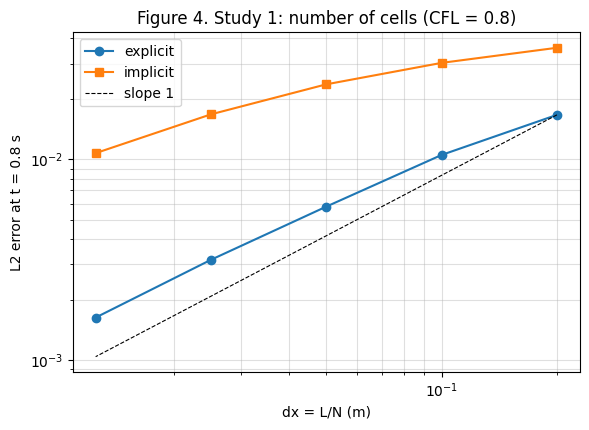

In [5]:
# ---- Study 1: number of cells (CFL target 0.8)
rows = []
for n in (50, 100, 200, 400, 800):
    rows.append((n, run(n, .8, 'exp'), run(n, .8, 'imp')))
print('Table 3. Study 1: number of cells (CFL target 0.8)')
print(f"{'N':>5s}{'w/dx':>6s}{'steps':>7s} | {'L2 exp':>9s}{'peak exp':>10s} | {'L2 imp':>9s}{'peak imp':>10s}")
for n, e, i in rows:
    print(f"{n:>5d}{width/e['dx']:>6.1f}{e['steps']:>7d} | {e['l2']:>9.5f}{e['peak']:>10.4f} | {i['l2']:>9.5f}{i['peak']:>10.4f}")
print('error ratios per doubling (explicit):', [round(rows[k][1]['l2']/rows[k+1][1]['l2'], 2) for k in range(4)])
print('error ratios per doubling (implicit):', [round(rows[k][2]['l2']/rows[k+1][2]['l2'], 2) for k in range(4)])

dxs = [r[1]['dx'] for r in rows]
plt.figure(figsize=(6, 4.4))
plt.loglog(dxs, [r[1]['l2'] for r in rows], 'o-', label='explicit')
plt.loglog(dxs, [r[2]['l2'] for r in rows], 's-', label='implicit')
plt.loglog(dxs, [rows[0][1]['l2']*d/dxs[0] for d in dxs], 'k--', lw=.8, label='slope 1')
plt.xlabel('dx = L/N (m)'); plt.ylabel('L2 error at t = 0.8 s'); plt.title('Figure 4. Study 1: number of cells (CFL = 0.8)')
plt.grid(alpha=.4, which='both'); plt.legend(); plt.tight_layout(); plt.show()

Table 4. Study 2: explicit time step (N = 200)
 target  lambda  steps   L2 error    peak  max |eta|
   0.10   0.100    502   1.68e-02   0.645     0.0322
   0.20   0.200    251   1.57e-02   0.667     0.0333
   0.40   0.398    126   1.31e-02   0.718     0.0358
   0.60   0.597     84   9.95e-03   0.783     0.0391
   0.80   0.795     63   5.82e-03   0.871     0.0435
   0.90   0.895     56   3.24e-03   0.928     0.0463
   1.00   0.983     51   5.79e-04   0.987     0.0492
   1.05   1.044     48   1.56e-03   1.035     0.0516
   1.10   1.089     46   3.31e-03   1.075     0.0536
   1.50   1.474     34   2.93e-02   1.696     0.0846
   2.00   1.927     26   1.56e-01   3.494      0.183


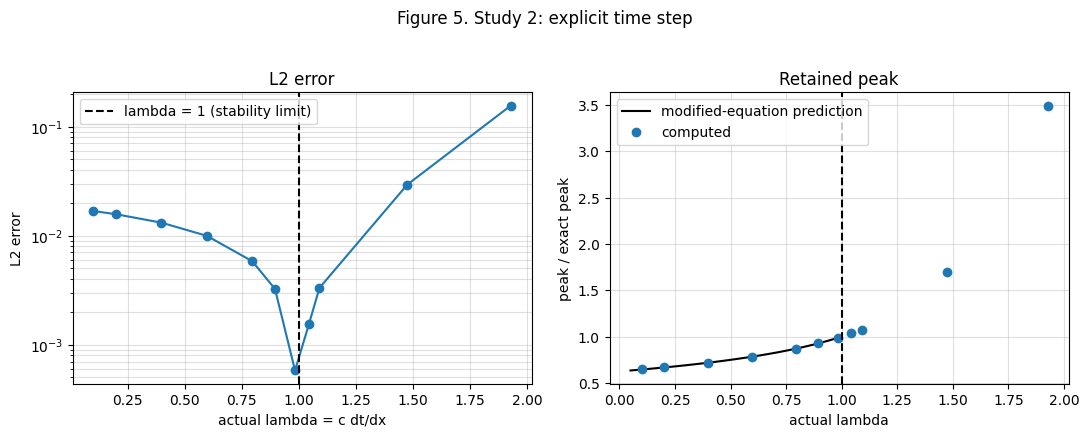

In [6]:
# ---- Study 2: explicit time step (N = 200), CFL target from 0.1 to 2
exp_rows = [(cfl, run(200, cfl, 'exp')) for cfl in (.1, .2, .4, .6, .8, .9, 1.0, 1.05, 1.1, 1.5, 2.0)]
print('Table 4. Study 2: explicit time step (N = 200)')
print(f"{'target':>7s}{'lambda':>8s}{'steps':>7s}{'L2 error':>11s}{'peak':>8s}{'max |eta|':>11s}")
for cfl, e in exp_rows:
    print(f"{cfl:>7.2f}{e['lam']:>8.3f}{e['steps']:>7d}{e['l2']:>11.2e}{e['peak']:>8.3f}{np.max(np.abs(e['eta'])):>11.3g}")

stable = [(e['lam'], e) for _, e in exp_rows if e['lam'] <= 1]
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
ax[0].semilogy([e['lam'] for _, e in exp_rows], [e['l2'] for _, e in exp_rows], 'o-')
ax[0].axvline(1, color='k', ls='--', label='lambda = 1 (stability limit)'); ax[0].set(xlabel='actual lambda = c dt/dx', ylabel='L2 error', title='L2 error'); ax[0].legend(); ax[0].grid(alpha=.4, which='both')
lam_g = np.linspace(.05, 1, 100)
ax[1].plot(lam_g, peak_prediction(0.5*c*(L/200)*(1 - lam_g)), 'k-', label='modified-equation prediction')
ax[1].plot([e['lam'] for _, e in exp_rows], [e['peak'] for _, e in exp_rows], 'o', label='computed')
ax[1].axvline(1, color='k', ls='--'); ax[1].set(xlabel='actual lambda', ylabel='peak / exact peak', title='Retained peak'); ax[1].legend(); ax[1].grid(alpha=.4)
fig.suptitle('Figure 5. Study 2: explicit time step', y=1.03); plt.tight_layout(); plt.show()

Table 5. Study 3: implicit time step (N = 200)
 target  lambda  steps   L2 error    peak   vol err
    0.2   0.200    251    0.01960   0.592   2.2e-14
    0.4   0.398    126    0.02112   0.563   8.2e-15
    0.8   0.795     63    0.02363   0.516   6.7e-15
    1.6   1.566     32    0.02714   0.452   3.9e-16
    3.2   3.132     16    0.03154   0.375   7.8e-16
    6.4   6.264      8    0.03615   0.299   0.0e+00
   12.8  12.528      4    0.04037   0.238   3.9e-16
   25.6  25.057      2    0.04383   0.204   7.8e-16


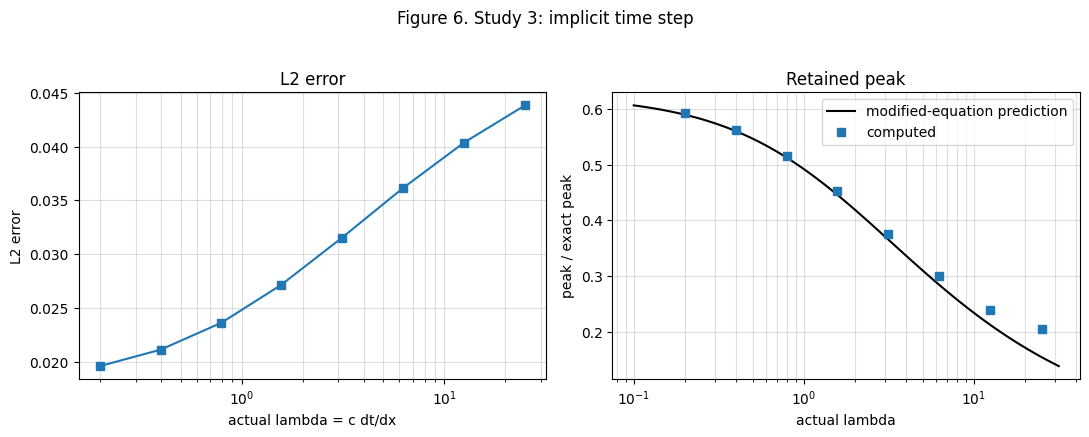

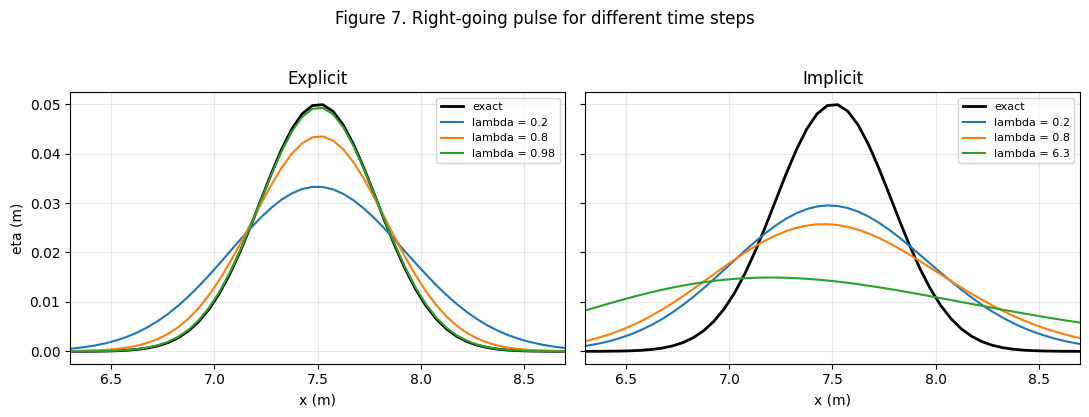

In [7]:
# ---- Study 3: implicit time step (N = 200), CFL target from 0.2 to 25.6
imp_rows = [(cfl, run(200, cfl, 'imp')) for cfl in (.2, .4, .8, 1.6, 3.2, 6.4, 12.8, 25.6)]
print('Table 5. Study 3: implicit time step (N = 200)')
print(f"{'target':>7s}{'lambda':>8s}{'steps':>7s}{'L2 error':>11s}{'peak':>8s}{'vol err':>10s}")
for cfl, e in imp_rows:
    print(f"{cfl:>7.1f}{e['lam']:>8.3f}{e['steps']:>7d}{e['l2']:>11.5f}{e['peak']:>8.3f}{e['vol']:>10.1e}")

fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
ax[0].semilogx([e['lam'] for _, e in imp_rows], [e['l2'] for _, e in imp_rows], 's-'); ax[0].set(xlabel='actual lambda = c dt/dx', ylabel='L2 error', title='L2 error'); ax[0].grid(alpha=.4, which='both')
lam_g = np.logspace(-1, 1.5, 100)
ax[1].semilogx(lam_g, peak_prediction(0.5*c*(L/200)*(1 + lam_g)), 'k-', label='modified-equation prediction')
ax[1].semilogx([e['lam'] for _, e in imp_rows], [e['peak'] for _, e in imp_rows], 's', label='computed')
ax[1].set(xlabel='actual lambda', ylabel='peak / exact peak', title='Retained peak'); ax[1].legend(); ax[1].grid(alpha=.4, which='both')
fig.suptitle('Figure 6. Study 3: implicit time step', y=1.03); plt.tight_layout(); plt.show()

# pulse shapes near the right-going pulse
fig, ax = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
ex = run(200, .8, 'exp')
for k, (cfl, s) in enumerate((('exp', 'explicit'), ('imp', 'implicit'))):
    ax[k].plot(ex['x'], ex['exact'], 'k-', lw=2, label='exact')
ax[0].plot(ex['x'], run(200, .2, 'exp')['eta'], label='lambda = 0.2'); ax[0].plot(ex['x'], run(200, .8, 'exp')['eta'], label='lambda = 0.8'); ax[0].plot(ex['x'], run(200, 1.0, 'exp')['eta'], label='lambda = 0.98')
ax[1].plot(ex['x'], run(200, .2, 'imp')['eta'], label='lambda = 0.2'); ax[1].plot(ex['x'], run(200, .8, 'imp')['eta'], label='lambda = 0.8'); ax[1].plot(ex['x'], run(200, 6.4, 'imp')['eta'], label='lambda = 6.3')
for a, t in zip(ax, ('Explicit', 'Implicit')): a.set(xlim=(6.3, 8.7), xlabel='x (m)', title=t); a.grid(alpha=.3); a.legend(fontsize=8)
ax[0].set_ylabel('eta (m)'); fig.suptitle('Figure 7. Right-going pulse for different time steps', y=1.03); plt.tight_layout(); plt.show()

## 5. Conclusions
* Both schemes conserve volume to round-off (periodic, conservative finite volumes).
* Both are first-order upwind schemes, whose main error is numerical diffusion $D_{num}=\tfrac12c\Delta x(1\mp\lambda)$; the retained pulse height predicted from it agrees with the computation to 0.4 percentage points.
* Explicit: stable for $\lambda\le1$ and most accurate near $\lambda=1$; reducing the time step *increases* the error. Implicit: stable for all $\lambda$ but increasingly diffusive as $\lambda$ grows.
* Error converges at about first order in $\Delta x$ (explicit factors approach 2 per doubling); at least about 8 cells across the pulse are needed for a reasonable amplitude ($N=200$ keeps 87% explicit, 52% implicit).
* To improve accuracy: refine the grid, use $\lambda$ close to 1 with the explicit scheme, or use a higher-order scheme (Lax-Wendroff, second-order upwind with limiters) or Crank-Nicolson time stepping.